<a href="https://colab.research.google.com/github/barakkajuwita-commits/Project-TIM-2-Diskon-Tarif-Tol/blob/main/JUWITA_PDS_TUGAS_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JUWITA (250907500007) A25 BISDIG
#REGRESI LINEAR BERGANDA - KOTA MAKASSAR
##Saya Mengambil Variabel kota Makassar yaitu:
Variabel dependent (Y) : PAD (Pendapatan asli daerah)
Variabel independent
(X1): DBH_PAJAK
(X2) : DAU_Grant

##IMPORT LIBRARY

In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import matplotlib.pyplot as plt

##IMPORT & FILTER KOTA MAKASSAR

In [5]:
#Membaca dan memiih dataset
df = pd.read_csv('dataset_fiskal_97_hipoFull.csv')
# Memfilter khusus untuk Kota Makassar
df_mks = df[df['Kota'] == 'Kota Makassar'].copy()


##MENENTUKAN VARIABEL DEPENDEN DAN INDPENDEN

In [8]:
# Variabel Dependen (Y) : PAD (Pendapatan Asli Daerah)
target_y = 'PAD'

# Variabel Independen
x1_col = 'DBH_PAJAK'
x2_col = 'DAU_Grant' # Ditambahkan sebagai X2 agar bisa membentuk bidang 3D

y = df_mks[target_y]
X1 = df_mks[x1_col]
X2 = df_mks[x2_col]

# Membentuk dataframe independen
X = pd.DataFrame({x1_col: X1, x2_col: X2})
X_sm = sm.add_constant(X)

##PERMODELAN REGRESI OLS

In [9]:
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# Mengambil parameter persamaan
b0 = model.params['const']
b1 = model.params[x1_col]
b2 = model.params[x2_col]
r_squared = model.rsquared

                            OLS Regression Results                            
Dep. Variable:                    PAD   R-squared:                       0.360
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                     2.248
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.168
Time:                        05:22:45   Log-Likelihood:                -60.378
No. Observations:                  11   AIC:                             126.8
Df Residuals:                       8   BIC:                             128.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        131.0270    146.250      0.896      0.3

##VISUALISASI 3D

In [19]:
fig = go.Figure()

# A. Bidang Regresi (Surface)
fig.add_trace(go.Surface(
    x=x1_range,
    y=x2_range,
    z=y_grid,
    colorscale='Viridis',
    opacity=0.75,
    name='Bidang Regresi'
))

# B. Titik Data Aktual dengan Label Tahun
fig.add_trace(go.Scatter3d(
    x=X1,
    y=X2,
    z=y,
    mode='markers+text',
    marker=dict(size=6, color=y, colorscale='Viridis', opacity=0.9, showscale=True),
    text=df_mks['Tahun'].apply(lambda t: f"Tahun {t}"),
    textposition="top center",
    name='Data Aktual'
))

# PENGATURAN LAYOUT
title_text = f"REGRESI LINEAR BERGANDA 3D – KOTA MAKASSARŶ = {b0:.3f} + ({b1:.3f}) X₁ + ({b2:.3f}) X₂ | R² = {r_squared:.3f}"

fig.update_layout(
    title=dict(text=title_text, x=0.5, font=dict(size=15)),
    scene=dict(
        xaxis={"title": f"DBH Pajak (X₁)"},
        yaxis={"title": f"DAU Grant (X₂)"},
        zaxis={"title": f"PAD (Y)"},
    ),
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98},
)

# MENAMPILKAN & MENYIMPAN KE FILE HTML

# Menampilkan grafik di Google Colab
fig.show()

# Menyimpan grafik sebagai file HTML agar bisa di-upload ke GitHub
fig.write_html("regresi_3d_kota_makassar.html")
print("File HTML berhasil disimpan sebagai 'regresi_3d_kota_makassar.html'!")


File HTML berhasil disimpan sebagai 'regresi_3d_kota_makassar.html'!


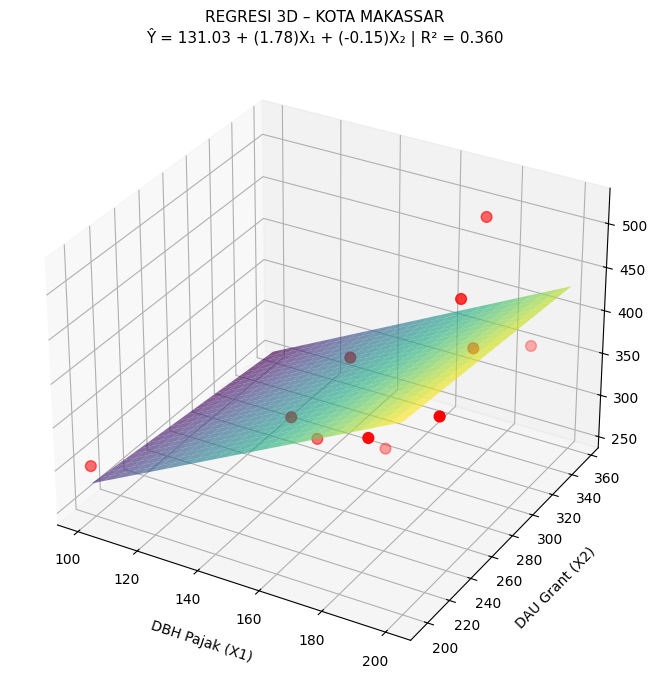

In [20]:
#Membuat Plot 3D Statis dengan Matplotlib
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

# Scatter titik data aktual Kota Makassar
ax.scatter(X1, X2, y, color='red', s=60, label='Data Aktual')

# Membuat grid bidang regresi
x1_range = np.linspace(X1.min(), X1.max(), 25)
x2_range = np.linspace(X2.min(), X2.max(), 25)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
y_grid = b0 + b1 * x1_grid + b2 * x2_grid

# Menampilkan bidang regresi (surface)
ax.plot_surface(x1_grid, x2_grid, y_grid, cmap='viridis', alpha=0.65)

# Label sumbu dan judul
ax.set_xlabel('DBH Pajak (X1)', labelpad=10)
ax.set_ylabel('DAU Grant (X2)', labelpad=10)
ax.set_zlabel('PAD (Y)', labelpad=10)
plt.title(f"REGRESI 3D – KOTA MAKASSAR\nŶ = {b0:.2f} + ({b1:.2f})X₁ + ({b2:.2f})X₂ | R² = {model.rsquared:.3f}", fontsize=11)

plt.tight_layout()
plt.show()
